In [20]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from itertools import combinations, permutations

3.a

In [3]:
def betweenness_of_node(G, v, normalized=True):
    """Shortest-path betweenness centrality of a single node v in graph G. Based
    on networkx.betweenness_centrality.
    Sums over all pairs (s, t) not including v, the fraction of shortest
    s-t paths that pass through v. 
    can be normalized to compare different graphs with various |V|
    """
    directed = G.is_directed()
    others = [n for n in G.nodes if n != v]
    # Directed: (s, t) and (t, s) are different pairs. Undirected: same pair.
    pairs = permutations(others, 2) if directed else combinations(others, 2)
    score = 0
    for s, t in pairs:
        try:
            paths = list(nx.all_shortest_paths(G, s, t))
        except nx.NetworkXNoPath:
            continue  
        through_v = 0
        for path in paths:
            if v in path:
                through_v += 1
        score += through_v / len(paths)
    if normalized:
        n = G.number_of_nodes()
        if n < 3:
            return 0  # no pairs excluding v, so P would be 0
        P = (n - 1) * (n - 2) if directed else (n - 1) * (n - 2) / 2
        score /= P

    return score

We will use the karate club graph to test some nodes

In [17]:
G = nx.karate_club_graph()
print(list(G.nodes))
print('mine: ', round(betweenness_of_node(G, 33, normalized=False), 4), 
      'networkx: ', round(nx.betweenness_centrality(G, normalized=False)[33], 4))
print('mine: ', round(betweenness_of_node(G, 0, normalized=False), 4), 
      'networkx: ', round(nx.betweenness_centrality(G, normalized=False)[0], 4))
print('mine: ', round(betweenness_of_node(G, 17, normalized=False), 4), 
      'networkx: ', round(nx.betweenness_centrality(G, normalized=False)[17], 4))

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
mine:  160.5516 networkx:  160.5516
mine:  231.0714 networkx:  231.0714
mine:  0.0 networkx:  0.0


Ok, that is working. Let's test on a digraph.

True


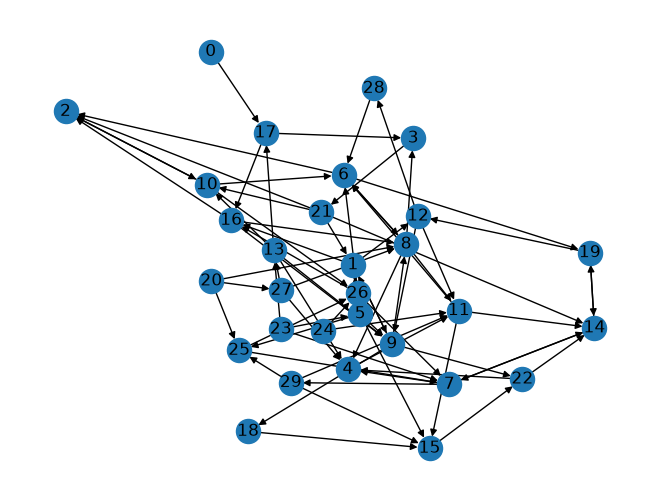

In [31]:
H = nx.erdos_renyi_graph(30, 0.10, directed=True)
print(H.is_directed())
nx.draw(H, with_labels=True)
plt.show()

We'll select 3 nodes and check vs networkx

In [30]:
print('mine: ', round(betweenness_of_node(H, 10, normalized=False), 4), 
      'networkx: ', round(nx.betweenness_centrality(H, normalized=False)[10], 4))
print('mine: ', round(betweenness_of_node(H, 19, normalized=False), 4), 
      'networkx: ', round(nx.betweenness_centrality(H, normalized=False)[19], 4))
print('mine: ', round(betweenness_of_node(H, 13, normalized=False), 4), 
      'networkx: ', round(nx.betweenness_centrality(H, normalized=False)[13], 4))

mine:  83.0373 networkx:  83.0373
mine:  44.0167 networkx:  44.0167
mine:  8.3333 networkx:  8.3333


Below we have separate if statements that handle the wrong type, if the node does not exist, and the divide by zero case (if $n<3$). the try: / except already handles missing paths, and we have an additional if statement for the fully empty case. 

In [32]:
def betweenness_of_node_augmented(G, v, normalized=True):
    """Shortest-path betweenness centrality of a single node v in graph G. Based
    on networkx.betweenness_centrality.
    Sums over all pairs (s, t) not including v, the fraction of shortest
    s-t paths that pass through v. 
    """
    if not isinstance(G, nx.Graph): 
        raise TypeError("G must be a NetworkX graph.")
    if v not in G:
        raise nx.NodeNotFound(f"Node {v} is not in the graph.")
    if G.number_of_edges() == 0:
        return 0.0
    directed = G.is_directed()
    others = [n for n in G.nodes if n != v]
    # Directed: (s, t) and (t, s) are different pairs. Undirected: same pair.
    pairs = permutations(others, 2) if directed else combinations(others, 2)
    score = 0.0
    for s, t in pairs:
        try:
            paths = list(nx.all_shortest_paths(G, s, t))
        except nx.NetworkXNoPath:
            continue  
        through_v = 0
        for path in paths:
            if v in path:
                through_v += 1
        score += through_v / len(paths)
    if normalized:
        n = G.number_of_nodes()
        if n < 3:
            return 0.0  # no pairs excluding v, so P would be 0
        P = (n - 1) * (n - 2) if directed else (n - 1) * (n - 2) / 2
        score /= P
    return score

Below we will test 5 potential edge cases using my original function, networkx, and my augmented function.

In [34]:
# 1) Not a NetworkX graph
try:
    betweenness_of_node({0: [1], 1: [0]}, 0)
except TypeError as e:
    print("Case 1:", e)



AttributeError: 'dict' object has no attribute 'is_directed'

broke on the directed check. 

In [36]:
# 2) Empty graph
try:
    betweenness_of_node(nx.Graph(), 0)
except nx.NodeNotFound as e:
    print("Case 2:", e)
print(betweenness_of_node(nx.Graph(), 0))



0


Successfully ran, but simply returned zero after finding no paths. 

In [38]:
# 3) Node 50 not in karate club
try:
    betweenness_of_node(G, 50)
except nx.NodeNotFound as e:
    print("Case 3:", e)
print(betweenness_of_node(G, 50))

0.0


also just ran and printed zero due to no valid paths.

In [39]:
# 4) Two nodes, one edge
G2 = nx.Graph([(0, 1)])
print("Case 4:", betweenness_of_node(G2, 0))

Case 4: 0


In [40]:
# 5) Two nodes, no edges
G3 = nx.Graph()
G3.add_nodes_from([0, 1])
print("Case 5:", betweenness_of_node(G3, 0))

Case 5: 0


Now, we will check my augmented function.

In [41]:
# 1) Not a NetworkX graph
try:
    betweenness_of_node_augmented({0: [1], 1: [0]}, 0)
except TypeError as e:
    print("Case 1:", e)

Case 1: G must be a NetworkX graph.


In [44]:
try:
    betweenness_of_node_augmented(nx.Graph(), 0)
except nx.NodeNotFound as e:
    print("Case 2:", e)

Case 2: Node 0 is not in the graph.


In [46]:
try:
    betweenness_of_node_augmented(G, 50)
except nx.NodeNotFound as e:
    print("Case 3:", e)

Case 3: Node 50 is not in the graph.


In [48]:
# 4) Two nodes, one edge
print("Case 4:", betweenness_of_node_augmented(G2, 0))

Case 4: 0.0


Continues to correctly print 0.

In [49]:
# 5) Two nodes, no edges
print("Case 5:", betweenness_of_node_augmented(G3, 0))

Case 5: 0.0


Finally, let's see how networkx function handles the same 5 cases.

In [51]:
# 1) Not a NetworkX graph
try:
    nx.betweenness_centrality({0: [1], 1: [0]}, 0)
except TypeError as e:
    print("Case 1:", e)

AttributeError: 'dict' object has no attribute 'nodes'

Errors on the lack of nodes, but failed on an AttributeError instead, so didn't hit the error message.

In [59]:

# 2) Empty graph
result = nx.betweenness_centrality(nx.Graph())
print("Case 2:", result)  


Case 2: {}


In [60]:
# 3) Node 50 not in karate club
result = nx.betweenness_centrality(G)
print("Case 3:", result[50])

KeyError: 50

Again, errors on the node not in the graph but as a KeyError

In [56]:
print("Case 4:", nx.betweenness_centrality(G2)[0])
print("Case 5:", nx.betweenness_centrality(G3)[0])

Case 4: 0.0
Case 5: 0.0


Networkx seems to handle the $n<3$ case properly. 